# 01 · FP&A baselines

How well do the simple rules an FP&A team uses forecast quarterly revenue? Every model in later sessions has to beat these.

- **B0, last quarter:** every future quarter = the latest known quarter. A sanity check only.
- **B1, same quarter last year:** next Q3 = last year's Q3. Seasonality, no growth.
- **B2, same quarter last year × (1 + growth):** B1 scaled by how much the last 4 known quarters grew vs the 4 before them.

**Setup (fixed, see CLAUDE.md):** rolling origin from 2013 Q1 to 2026 Q2. At each origin we use only quarters whose first filing was at most 65 days after the origin quarter ended. Horizons h = 1–4 quarters. The main run uses first-reported revenue; the check uses latest revenue. The code is in `src/baselines.py` and `src/evaluate_baselines.py`.

## Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from evaluate_baselines import errors, metric_table, table_2020

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
first = errors("revenue_first_reported")      # main run
latest = errors("revenue_latest")             # check
first[first["baseline"] == "B1"].groupby(["company", "h"]).size().unstack().rename_axis(columns="forecasts per baseline, by h")

"forecasts per baseline, by h",1,2,3,4
company,,,,
Alphabet,54,53,52,51
Caterpillar,54,53,52,51
Mattel,54,53,52,51


## 1. MAPE: average % miss
MAPE = average of |actual − forecast| / actual, in %. "Full year" is the % miss on the sum of the next 4 quarters, from one origin. For Alphabet we also show the results without targets 2012 Q2–2014 Q4 (the Motorola restatements).

In [2]:
metric_table(first, "ape").round(1)

h=1   h=2   h=3   h=4  full year
company                 baseline                                   
Mattel                  B0       44.70 71.40 41.10  9.40      32.20
                        B1        8.90  9.00  9.10  9.40       6.40
                        B2        8.90  9.80 10.10 11.20       7.70
Caterpillar             B0        7.20  8.10 12.20 13.90       9.20
                        B1       14.10 14.00 13.80 13.90      12.30
                        B2       12.00 15.00 17.50 19.70      15.20
Alphabet                B0        7.30  9.10 11.70 14.70      10.10
                        B1       15.10 15.50 15.20 14.70      15.10
                        B2        5.80  7.40  8.50  9.10       6.70
Alphabet excl. Motorola B0        7.50  9.20 11.90 15.20      10.40
                        B1       15.20 15.20 15.20 15.20      15.20
                        B2        5.70  7.10  8.20  8.80       7.20

**What this shows:** each company has a different winner. For **Mattel**, B1 (same quarter last year) is best at about 9 % per quarter and 6.4 % for the full year; B2 ties at h = 1 and falls behind further out. For **Alphabet**, B2 wins clearly (5.7 % vs 15.2 % without the Motorola quarters), because B1 ignores steady growth. For **Caterpillar**, the sanity check B0 (last quarter) beats both FP&A rules (7.2 % vs 12.0–14.1 % at h = 1): its revenue has little seasonality but long cycles, so year-old information is stale.

## 2. MASE: compared with "same quarter last year"
MASE divides each miss by how far off "same quarter last year" was, on average, on the quarters known at that origin. **Below 1** = the forecast did better than that naive rule did on past data. **Above 1** = worse.

In [3]:
metric_table(first, "ase").round(2)

h=1  h=2  h=3  h=4
company                 baseline                    
Mattel                  B0       4.94 8.50 5.12 1.19
                        B1       1.12 1.15 1.15 1.19
                        B2       1.16 1.24 1.26 1.42
Caterpillar             B0       0.39 0.44 0.64 0.73
                        B1       0.74 0.74 0.74 0.73
                        B2       0.63 0.79 0.93 1.05
Alphabet                B0       1.04 1.34 1.81 2.33
                        B1       2.11 2.24 2.29 2.33
                        B2       0.82 1.07 1.28 1.41
Alphabet excl. Motorola B0       1.12 1.41 1.90 2.45
                        B1       2.24 2.32 2.39 2.45
                        B2       0.85 1.10 1.31 1.44

**What this shows:** MASE tells the same story on a common scale. For Mattel, nothing beats the in-sample "same quarter last year" error (all ≥ 1.12), so its quarters are simply hard to predict. Alphabet's B2 is below 1 only at h = 1 (0.85). Caterpillar's values are all below 1 at h = 1, but mostly because its in-sample period includes the 2009 crash and 2010–2011 rebound: year-on-year swings averaged \$4.2 bn then vs \$1.9 bn from 2012 on, which makes the scale large.

## 3. The year 2020
MAPE for target quarters in 2020 (the pandemic) vs all other years. Alphabet is shown without the Motorola quarters.

In [4]:
table_2020(first).round(1)

h=1             all h            
targets                           2020 other years  2020 other years
company                 baseline                                    
Mattel                  B0       55.60       43.90 54.00       41.00
                        B1       13.00        8.60 13.00        8.80
                        B2       14.20        8.50 12.50        9.80
Caterpillar             B0       10.80        6.90 20.80        9.40
                        B1       29.30       12.90 29.30       12.70
                        B2       18.10       11.50 27.40       15.00
Alphabet excl. Motorola B0       13.80        6.90 12.80       10.80
                        B1       11.20       15.60 11.20       15.60
                        B2        9.00        5.40  9.20        7.30

**What this shows:** 2020 roughly doubled the misses for Mattel and Caterpillar. Caterpillar's B1 missed by 29 % on average, because it forecast 2020 from the strong 2019 quarters. Alphabet's B1 actually did *better* in 2020 (11.2 % vs 15.6 %): growth stalled for once, which is exactly what B1 assumes.

## 4. Check: first-reported vs latest revenue
The same MAPE when everything (inputs and actuals) uses the latest, restated revenue instead.

In [5]:
check = pd.concat({"first reported": metric_table(first, "ape"),
                   "latest": metric_table(latest, "ape")}, axis=1)
check.loc[:, [(s, c) for c in ["h=1", "full year"] for s in ["first reported", "latest"]]].round(2)

first reported latest first reported  \
                                            h=1    h=1      full year   
company                 baseline                                        
Mattel                  B0                44.72  44.70          32.20   
                        B1                 8.89   8.88           6.36   
                        B2                 8.92   8.92           7.72   
Caterpillar             B0                 7.22   7.22           9.23   
                        B1                14.07  14.07          12.32   
                        B2                11.98  11.98          15.25   
Alphabet                B0                 7.32   7.19          10.05   
                        B1                15.09  15.29          15.06   
                        B2                 5.80   6.09           6.71   
Alphabet excl. Motorola B0                 7.51   7.51          10.40   
                        B1                15.20  15.20          15.25   
                        B2                 5.66   5.81           7.19   

                                    latest  
                                 full year  
company                 baseline            
Mattel                  B0           32.18  
                        B1            6.35  
                        B2            7.72  
Caterpillar             B0            9.23  
                        B1           12.32  
                        B2           15.25  
Alphabet                B0           10.31  
                        B1           15.42  
                        B2            6.50  
Alphabet excl. Motorola B0           10.40  
                        B1           15.25  
                        B2            7.07

**What this shows:** using the latest (restated) revenue barely changes anything. Mattel and Caterpillar move by at most 0.02 points, and Alphabet by at most 0.4 points (0.15 without the Motorola quarters). So the ranking of the baselines does not depend on restatements; but first-reported stays the honest choice for training.

## 5. Actuals vs B1 and B2, one quarter ahead (h = 1)
Each chart shows the first-reported revenue (solid) against the B1 (dashed) and B2 (dotted) forecasts made one quarter earlier. The grey band marks 2020. For Alphabet, a lighter band marks the Motorola targets.

In [6]:
ACTUAL, B1C, B2C = "#2a78d6", "#eb6834", "#1baf7a"      # default palette slots 1-3
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#e1e0d9", "#f0efec"
h1 = first[first["h"] == 1].pivot_table(index=["company", "target"], columns="baseline",
                                        values="forecast").join(
     first[first["h"] == 1].groupby(["company", "target"])["actual"].first())

def chart(company):
    d = h1.loc[company] / 1e9
    x = d.index.to_timestamp(how="end")
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color=BAND, zorder=0)
    if company == "Alphabet":
        ax.axvspan(x.min(), pd.Timestamp("2014-12-31"), color=BAND, alpha=0.6, zorder=0)
        ax.text(pd.Timestamp("2013-06-30"), 0.97, "Motorola", transform=ax.get_xaxis_transform(),
                color=MUTED, fontsize=9, va="top")
    ax.text(pd.Timestamp("2020-07-01"), 0.97, "2020", transform=ax.get_xaxis_transform(),
            color=MUTED, fontsize=9, va="top", ha="center")
    ax.plot(x, d["actual"], color=ACTUAL, lw=2, label="Actual (first reported)")
    ax.plot(x, d["B1"], color=B1C, lw=1.6, ls="--", label="B1 same quarter last year")
    ax.plot(x, d["B2"], color=B2C, lw=1.6, ls=":", label="B2 × (1 + growth)")
    mape = first[(first["company"] == company) & (first["h"] == 1)].groupby("baseline")["ape"].mean()
    ax.set_title(f"{company}: revenue vs forecasts one quarter ahead   "
                 f"(MAPE B1 {mape['B1']:.1f} %, B2 {mape['B2']:.1f} %)",
                 loc="left", color=INK, fontsize=12)
    ax.set_ylabel("Revenue, $bn", color=MUTED)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3, labelcolor=MUTED)
    fig.tight_layout()
    plt.show()

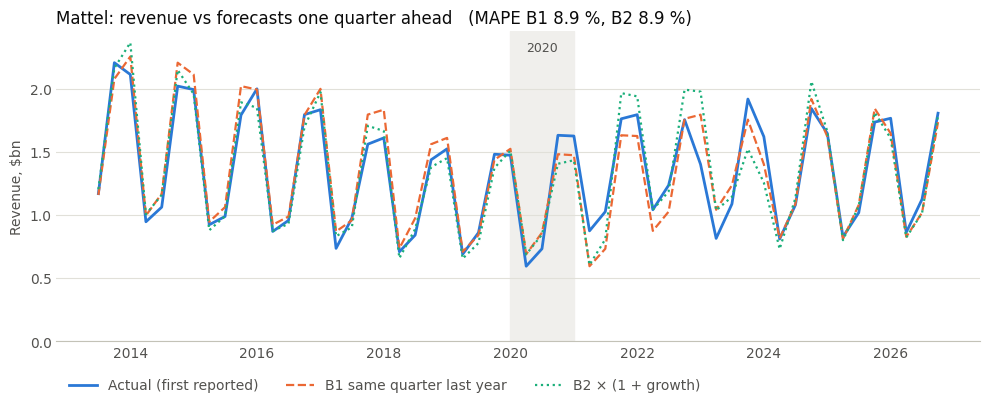

In [7]:
chart("Mattel")

**What this shows:** B1 and B2 follow Mattel's yearly saw-tooth well, because the seasonal pattern repeats. The big misses come when a year breaks the pattern: the 2021 rebound (B1 31–32 % too low) and the weak 2022 Q4 (B2 41 % too high, after a strong year made growth look good). B2 beats B1 in only 54 % of quarters, about a coin flip.

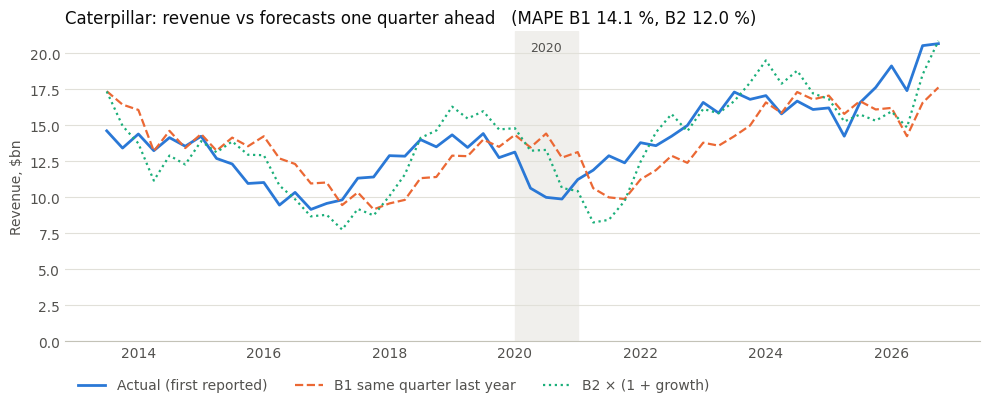

In [8]:
chart("Caterpillar")

**What this shows:** B1 (dashed) is the actual line shifted one year to the right, so it is always late at the turning points: too high in the 2015–2016 slump and in 2020 (+44 % in 2020 Q2). B2 (dotted) adds momentum, which helps in steady stretches but overshoots after turns: 31–35 % too low in early 2021, just as revenue recovered. Neither rule knows where the cycle is now, which is why "last quarter" (B0) does better.

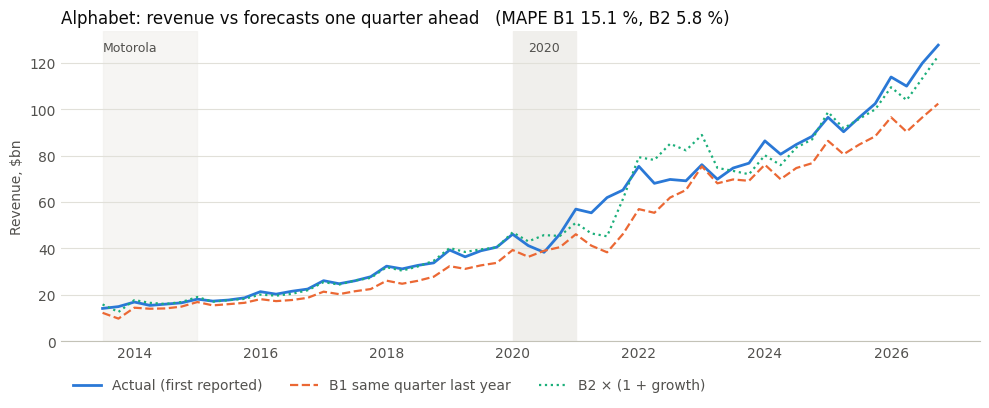

In [9]:
chart("Alphabet")

**What this shows:** B1 (dashed) sits below the actual line almost every quarter (it over-forecasts only 2 % of the time), because Alphabet grows about 15–20 % a year and B1 assumes zero growth. B2 (dotted) tracks the actual line closely and beats B1 in 91 % of quarters. Its misses come when growth changes speed: the 2021 boom (27 % too low in 2021 Q2) and the 2022 slowdown (19–22 % too high).

## Summary: the bar every model must clear

| Company | Best baseline (h = 1) | MAPE h = 1 | Full year | Bar for later models |
|---|---|---|---|---|
| Mattel | B1 (B2 tied) | 8.9 % | B1 6.4 % | beat B1 |
| Caterpillar | **B0** last quarter | 7.2 % | B0 9.2 % | beat B0, not just B1/B2 |
| Alphabet (excl. Motorola) | B2 | 5.7 % | B2 7.2 % | beat B2 |

No single FP&A rule wins everywhere: seasonality matters for Mattel, growth for Alphabet, the cycle for Caterpillar. Later models are judged against the best baseline for each company, with the same rolling origin, the same 65-day rule and first-reported revenue. A model that only matches these numbers adds nothing.